# Spam Detector using spamassassin corpus

## Loading and inspecting data

In [22]:
import os
import pathlib, glob
import pandas as pd

path = "data/spamassassin/"


sources = {
    "easy_ham": 0,
    "easy_ham_@": 0,
    "hard_ham": 0,
    "spam": 1,
    "spam_2": 1
}

email_list = []
label_list = []


for folder, label in sources.items():
    temp_files = glob.glob(os.path.join(path, folder, "*"))
    

    for file in temp_files:
        with open(file, "r", encoding="utf-8", errors="replace") as f:
            content = f.read()
            email_list.append(content)
            label_list.append(label)
    
df = pd.DataFrame({"emails": email_list,
                       "labels": label_list})
    
df_shuffled = df.sample(frac=1, random_state=42).reset_index(drop=True)

df_shuffled.head()

,emails,labels
0,From tazgirlcd@msn.com Wed Jul 3 12:07:43 20...,1
1,From rpm-list-admin@freshrpms.net Sat Oct 5 ...,0
2,From fork-admin@xent.com Mon Aug 26 15:32:10 ...,0
3,From fork-admin@xent.com Wed Oct 9 22:44:55 ...,0
4,From lomlaguatatuobrasrer@hotmail.com Mon Jun...,1


In [23]:
df_shuffled.labels.value_counts()

labels
0    2801
1    1898
Name: count, dtype: int64

In [63]:
df_shuffled["emails"][0]

'From fork-admin@xent.com  Tue Sep 24 10:48:34 2002\nReturn-Path: <fork-admin@xent.com>\nDelivered-To: yyyy@localhost.example.com\nReceived: from localhost (jalapeno [127.0.0.1])\n\tby jmason.org (Postfix) with ESMTP id B899416F03\n\tfor <jm@localhost>; Tue, 24 Sep 2002 10:48:33 +0100 (IST)\nReceived: from jalapeno [127.0.0.1]\n\tby localhost with IMAP (fetchmail-5.9.0)\n\tfor jm@localhost (single-drop); Tue, 24 Sep 2002 10:48:33 +0100 (IST)\nReceived: from xent.com ([64.161.22.236]) by dogma.slashnull.org\n    (8.11.6/8.11.6) with ESMTP id g8NN10C06961 for <jm@jmason.org>;\n    Tue, 24 Sep 2002 00:01:00 +0100\nReceived: from lair.xent.com (localhost [127.0.0.1]) by xent.com (Postfix)\n    with ESMTP id 04BAB2941D9; Mon, 23 Sep 2002 15:57:08 -0700 (PDT)\nDelivered-To: fork@example.com\nReceived: from crank.slack.net (slack.net [166.84.151.181]) by xent.com\n    (Postfix) with ESMTP id 8D22029409A for <fork@xent.com>; Mon,\n    23 Sep 2002 15:56:50 -0700 (PDT)\nReceived: by crank.slack.

In [68]:
df_shuffled.isna().sum()

emails    0
labels    0
dtype: int64

## Splitting Data

In [24]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(df_shuffled["emails"], df_shuffled["labels"], test_size=0.2, random_state=42,stratify=df_shuffled["labels"])

print(f"y train: {y_train.value_counts()}")
print(f"y test: {y_test.value_counts()}")


y train: labels
0    2241
1    1518
Name: count, dtype: int64
y test: labels
0    560
1    380
Name: count, dtype: int64


## Defining helper functions

In [25]:
from email import policy
import email
import re
import string

def cleanEmail(email_string):
    msg = email.message_from_string(email_string, policy=policy.default)
    body_part = msg.get_content()

    if body_part:
        return body_part
    return ""

def replaceUrls(email: str):
    url_pattern = r'https?://[^\s<>"]+|www\.[^\s<>"]+'
    replacedemail =re.sub(url_pattern, "WEBLINK", string=email)
    return replacedemail

def replaceEmailAddresses(email:str):
    email_pattern = r"[a-zA-Z0-9._%+-]+@[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}"
    repl_email=re.sub(pattern=email_pattern, repl="EMAILADDRESS", string=email)
    return repl_email

def replaceNumbers(email:str):
    pattern = r"\b\d{4,}\b"
    repl_email= re.sub(pattern=pattern, repl="NUMBER", string=email)
    return repl_email

def replaceEndOfLineCharacters(email:str):
    repl_email = email.replace("\n", " ")
    new_repl_email = " ".join(repl_email.split())
    return new_repl_email

def removePunct(email:str):
    translator = str.maketrans("","", string.punctuation)
    repl_email = email.translate(translator)
    return repl_email




In [83]:
print(replaceEndOfLineCharacters(replaceNumbers(removePunct(replaceEmailAddresses(replaceUrls(cleanEmail(x_train[88])))))).lower())

brandnew version 70 just released astounding new software lets you find out almost anything about anyone download it right now no charge card needed for the brandnew version 70 click here a hrefweblink weblink a discover everything you ever wanted to know about your friends your family your enemies your employees yourself is someone using your identity even your boss did you know you can search for anyone anytime anywhere right on the internet download this software right nowclick here a hrefweblink weblink a this mammoth collection of internet investigative tools research sites will provide you with nearly 400 gigantic search resources to locate information on people you trust screen new tenants or roommates housekeepers current or past employment people you work with license plate number with name and address unlisted phone numbers long lost friends locate emails phone numbers or addresses o get a copy of your fbi file o get a copy of your military file o find debtors and locate hidd

## Creating custom transformers

In [26]:
import email
import re
import string
from email import policy

from sklearn.base import BaseEstimator, TransformerMixin


class EmailCleaner(BaseEstimator, TransformerMixin):
    def __init__(self, remove_header = True, remove_punctuation = True) -> None:
        self.remove_header = remove_header
        self.remove_punctuation = remove_punctuation
        super().__init__()
        
    def fit(self, X, y=None):
        return self
    
    def cleanEmail(self, email_string):
        try:
            msg = email.message_from_string(email_string, policy=policy.default)
            body_part = msg.get_body(preferencelist=("plain", "html"))
            
            if body_part:
                try:
                    content = body_part.get_content()
                    if content:
                        return str(content)
                except (LookupError, UnicodeDecodeError, AttributeError):
                    pass

                payload = body_part.get_payload(decode=True)
                if isinstance(payload, bytes):
                    for enc in ("utf-8", "latin-1", "cp1252"):
                        try:
                            return payload.decode(enc)
                        except (UnicodeDecodeError, LookupError):
                            continue
                    return payload.decode("utf-8", errors="replace")
                elif isinstance(payload, str):
                    return payload
                    
        except Exception:
            pass
        parts = email_string.split("\n\n", 1)
        return parts[1] if len(parts) > 1 else email_string
    
    def replaceUrls(self, email: str):
        url_pattern = r'https?://[^\s<>"]+|www\.[^\s<>"]+'
        email =re.sub(url_pattern, "WEBLINK", string=email)
        return email
            
    def replaceEmailAddresses(self, email:str):
        email_pattern = r"[a-zA-Z0-9._%+-]+@[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}"
        email=re.sub(pattern=email_pattern, repl="EMAILADDRESS", string=email)
        return email
    
    def replaceNumbers(self, email:str):
        pattern = r"\b\d{4,}\b"
        email= re.sub(pattern=pattern, repl="NUMBER", string=email)
        return email
    
    def replaceEndOfLineCharacters(self, email:str):
        repl_email = email.replace("\n", " ")
        email = " ".join(repl_email.split())
        return email
    
    def removePunct(self, email:str):
        translator = str.maketrans("","", string.punctuation)
        email = email.translate(translator)
        return email
    
    def cleanSingleEmail(self, email):
        if self.remove_header:
            email = self.cleanEmail(email)
        email = self.replaceUrls(email)
        email = self.replaceEmailAddresses(email)
        if self.remove_punctuation:
            email = self.removePunct(email)
        email = self.replaceNumbers(email)
        email = self.replaceEndOfLineCharacters(email)
        
        return email.lower()
        
    
    def transform(self, X):
        return [self.cleanSingleEmail(email) for email in X]

## Making training pipeline

In [27]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import CountVectorizer

emailCleaner = EmailCleaner()
countVectorizer = CountVectorizer()

email_preprocessing_pipeline = Pipeline([("email_cleaner", emailCleaner), ("count_vectorizer", countVectorizer) ])



In [ ]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier()
final_model = Pipeline([("preprocessing", email_preprocessing_pipeline), ("knn", knn)])


## Training Models

### KNN Classifier

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.90      0.92      2241
           1       0.86      0.91      0.89      1518

    accuracy                           0.91      3759
   macro avg       0.90      0.91      0.90      3759
weighted avg       0.91      0.91      0.91      3759



[]

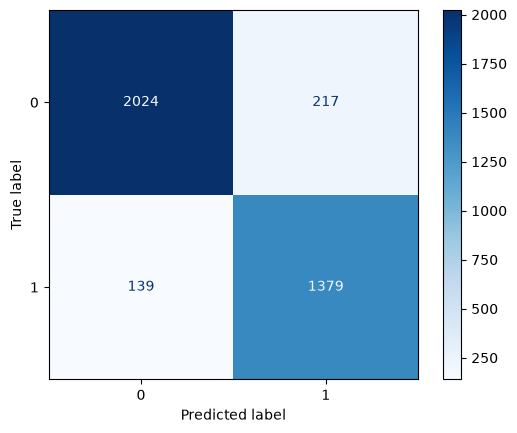

In [29]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import cross_val_predict
import matplotlib.pyplot as plt


pred = cross_val_predict(final_model, x_train, y_train, cv=5)

cr = classification_report(y_train, pred)
print("Classification Report:")
print(cr)
ConfusionMatrixDisplay.from_predictions(y_train, pred, cmap="Blues")
plt.plot()


### Logistic Regression

In [34]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=300)
final_model = Pipeline([("preprocessing", email_preprocessing_pipeline), ("lr", lr)])


Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.98      2241
           1       0.98      0.97      0.97      1518

    accuracy                           0.98      3759
   macro avg       0.98      0.98      0.98      3759
weighted avg       0.98      0.98      0.98      3759



[]

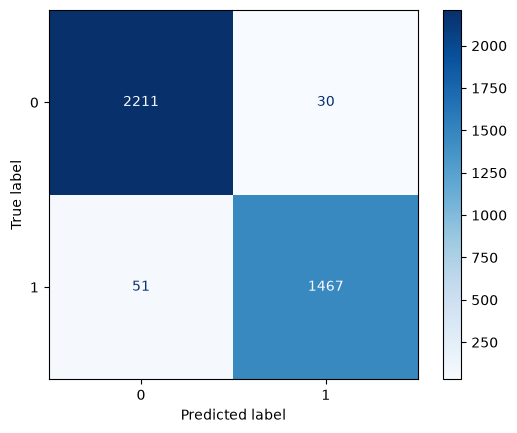

In [35]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import cross_val_predict
import matplotlib.pyplot as plt


pred = cross_val_predict(final_model, x_train, y_train, cv=5)

cr = classification_report(y_train, pred)
print("Classification Report:")
print(cr)
ConfusionMatrixDisplay.from_predictions(y_train, pred, cmap="Blues")
plt.plot()


### Random Forrest

In [36]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_jobs=-1)
final_model = Pipeline([("preprocessing", email_preprocessing_pipeline), ("rf", rf)])


Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98      2241
           1       0.98      0.96      0.97      1518

    accuracy                           0.98      3759
   macro avg       0.98      0.97      0.97      3759
weighted avg       0.98      0.98      0.98      3759



[]

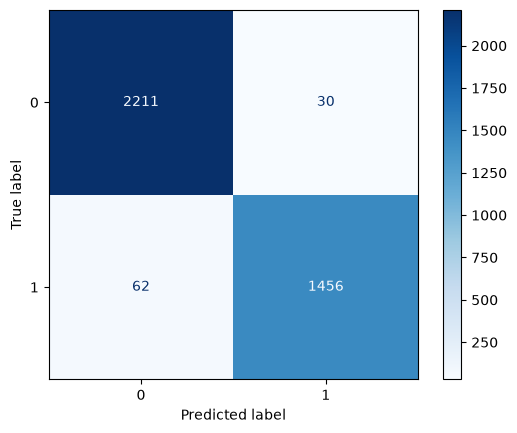

In [37]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import cross_val_predict
import matplotlib.pyplot as plt


pred = cross_val_predict(final_model, x_train, y_train, cv=5)

cr = classification_report(y_train, pred)
print("Classification Report:")
print(cr)
ConfusionMatrixDisplay.from_predictions(y_train, pred, cmap="Blues")
plt.plot()


Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.98      0.98       560
           1       0.97      0.96      0.97       380

    accuracy                           0.97       940
   macro avg       0.97      0.97      0.97       940
weighted avg       0.97      0.97      0.97       940



[]

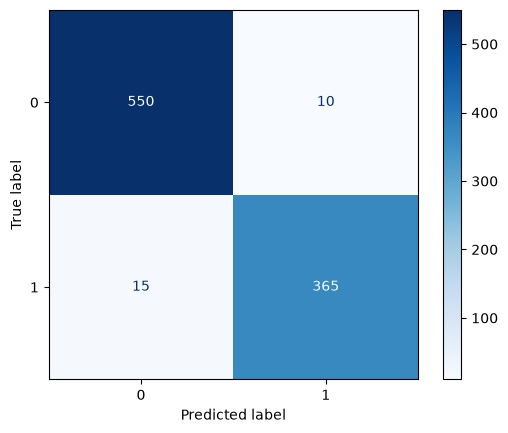

In [38]:

final_model.fit(x_train, y_train)

pred = final_model.predict(x_test)

cr = classification_report(y_test, pred)
print("Classification Report:")
print(cr)
ConfusionMatrixDisplay.from_predictions(y_test, pred, cmap="Blues")
plt.plot()

## Hyperparameter tuning on Random Forest

In [42]:
from sklearn.model_selection import GridSearchCV

grid = {
    "rf__n_estimators": [100, 300, 500],
    "rf__criterion": ["gini", "entropy", "log_loss"],
    "rf__max_depth": [None]
    
}

gs = GridSearchCV(final_model, grid, scoring="f1", verbose=1)

gs.fit(x_train, y_train)

print(gs.best_params_)
print(gs.best_score_)

Fitting 5 folds for each of 9 candidates, totalling 45 fits
{'rf__criterion': 'entropy', 'rf__max_depth': None, 'rf__n_estimators': 500}
0.9711292486277767


In [18]:
from sklearn.model_selection import GridSearchCV

grid = {
    "rf__n_estimators": [500, 800, 1000],
    "rf__criterion": ["entropy"],
    "rf__max_depth": [None]
    
}

gs = GridSearchCV(final_model, grid, scoring="f1", verbose=1)

gs.fit(x_train, y_train)

print(gs.best_params_)
print(gs.best_score_)

Fitting 5 folds for each of 3 candidates, totalling 15 fits
{'rf__criterion': 'entropy', 'rf__max_depth': None, 'rf__n_estimators': 500}
0.983710379470266


In [39]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_jobs=-1, criterion="entropy", max_depth=None, n_estimators=500)
final_model = Pipeline([("preprocessing", email_preprocessing_pipeline), ("rf", rf)])


Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.98      0.98      2241
           1       0.98      0.96      0.97      1518

    accuracy                           0.97      3759
   macro avg       0.98      0.97      0.97      3759
weighted avg       0.97      0.97      0.97      3759



[]

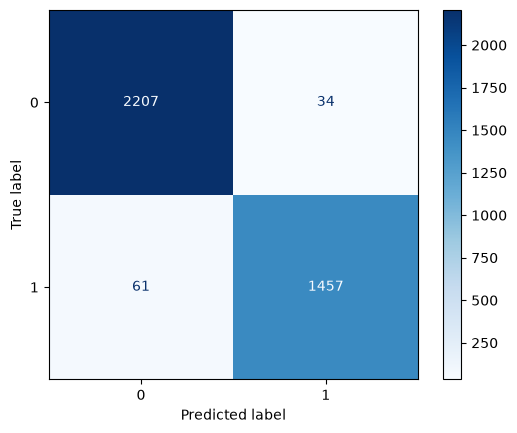

In [40]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import cross_val_predict
import matplotlib.pyplot as plt


pred = cross_val_predict(final_model, x_train, y_train, cv=5)

cr = classification_report(y_train, pred)
print("Classification Report:")
print(cr)
ConfusionMatrixDisplay.from_predictions(y_train, pred, cmap="Blues")
plt.plot()


Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.98      0.98       560
           1       0.98      0.96      0.97       380

    accuracy                           0.97       940
   macro avg       0.97      0.97      0.97       940
weighted avg       0.97      0.97      0.97       940



[]

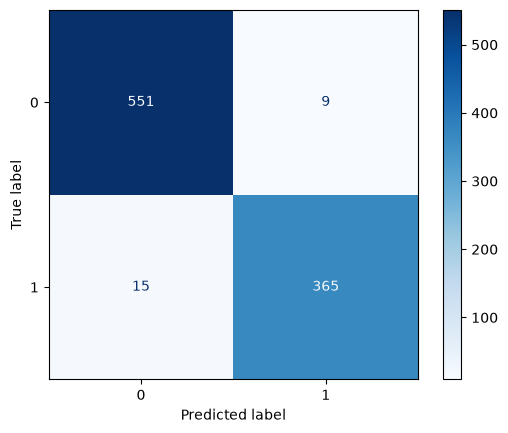

In [41]:

final_model.fit(x_train, y_train)

pred = final_model.predict(x_test)

cr = classification_report(y_test, pred)
print("Classification Report:")
print(cr)
ConfusionMatrixDisplay.from_predictions(y_test, pred, cmap="Blues")
plt.plot()